In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

In [24]:
# Load the preprocessed dataset
df = pd.read_csv('../Edge-IIoTset_ML-112.csv')

In [25]:
df.head(10)

,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,dns_4,dns_5,dns_6,dns_7,mqtt1_0,mqtt1_1,mqtt1_2,mqtt2_0,mqtt3_0,mqtt3_2
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,87.0,3.794211e+09,48707.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,59.0,6.828863e+08,19031.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,194.0,2.337571e+09,39685.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,16724.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.196863e+08,26682.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,0.0,0.0,9047.0,41365.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,365851987.0,3.658520e+08,56450.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,261.0,2.367878e+09,44524.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152245 entries, 0 to 152244
Data columns (total 73 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   arp.opcode               152245 non-null  float64
 1   arp.hw.size              152245 non-null  float64
 2   icmp.checksum            152245 non-null  float64
 3   icmp.seq_le              152245 non-null  float64
 4   icmp.transmit_timestamp  152245 non-null  float64
 5   http.content_length      152245 non-null  float64
 6   http.response            152245 non-null  float64
 7   tcp.ack                  152245 non-null  float64
 8   tcp.ack_raw              152245 non-null  float64
 9   tcp.checksum             152245 non-null  float64
 10  tcp.connection.fin       152245 non-null  float64
 11  tcp.connection.rst       152245 non-null  float64
 12  tcp.connection.syn       152245 non-null  float64
 13  tcp.connection.synack    152245 non-null  float64
 14  tcp.

In [27]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [28]:
print(df['Attack_type'].value_counts())

Attack_type
DDoS         48336
Injection    30048
Malware      29526
Normal       24141
Scanning     19836
MITM           358
Name: count, dtype: int64


In [29]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [30]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [31]:
# Apply the Chi-Squared test
chi_selector = SelectKBest(chi2, k='all')  # Set k to the desired number of features
X_kbest = chi_selector.fit_transform(X, y)

In [32]:
# Get the scores for each feature
chi_scores = chi_selector.scores_

# Combine scores with feature names
chi_scores = pd.DataFrame({'feature': X.columns, 'score': chi_scores})

# Sort the features by their scores
chi_scores = chi_scores.sort_values(by='score', ascending=False)

print(chi_scores)

                    feature         score
8               tcp.ack_raw  3.741190e+13
7                   tcp.ack  1.533944e+13
18                  tcp.seq  1.472715e+12
4   icmp.transmit_timestamp  4.262691e+10
20               udp.stream  4.109097e+10
..                      ...           ...
43                  http1_3  6.675187e+00
53                  http3_4  6.675187e+00
49                  http3_0  6.675187e+00
64                    dns_7  5.306491e+00
25   dns.retransmit_request  5.306491e+00

[71 rows x 2 columns]


In [33]:
selected_features = chi_scores['feature'].tolist()[:67]  # Select top k features

In [34]:
# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)

# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

In [35]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (106571, 67)
X_val shape: (15225, 67)
X_test shape: (30449, 67)


In [36]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [37]:
# Initialize the LightGBM classifier
def light_gbm_model():
    _model = LGBMClassifier(
        objective='multiclass',
        num_class=6,
        learning_rate=0.1,
        n_estimators=100,
        num_leaves=31,
        max_depth=-1,
        reg_alpha=0,
        reg_lambda=0.5,
        random_state=42
    )
    return _model

model = light_gbm_model()

In [38]:
# Train the model
model.fit(X_train, y_train, eval_set=(X_val, y_val), eval_metric=['multi_logloss', 'multi_error'])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008614 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2824
[LightGBM] [Info] Number of data points in the train set: 106571, number of used features: 58
[LightGBM] [Info] Start training from score -1.842267
[LightGBM] [Info] Start training from score -1.145780
[LightGBM] [Info] Start training from score -2.038795
[LightGBM] [Info] Start training from score -1.618828
[LightGBM] [Info] Start training from score -6.055106
[LightGBM] [Info] Start training from score -1.645561
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] N

LGBMClassifier(num_class=6, objective='multiclass', random_state=42,
               reg_alpha=0, reg_lambda=0.5)

In [39]:
# Predict on the test set
y_pred = model.predict(X_test)

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [40]:
y_pred_classes = y_pred

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))]))


Accuracy: 0.9755657000229893
Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      4837
        DDoS       0.98      0.99      0.99      9594
    Scanning       1.00      0.99      0.99      4004
   Injection       0.92      0.97      0.94      5892
        MITM       1.00      1.00      1.00        80
     Malware       0.99      0.93      0.96      6042

    accuracy                           0.98     30449
   macro avg       0.98      0.98      0.98     30449
weighted avg       0.98      0.98      0.98     30449



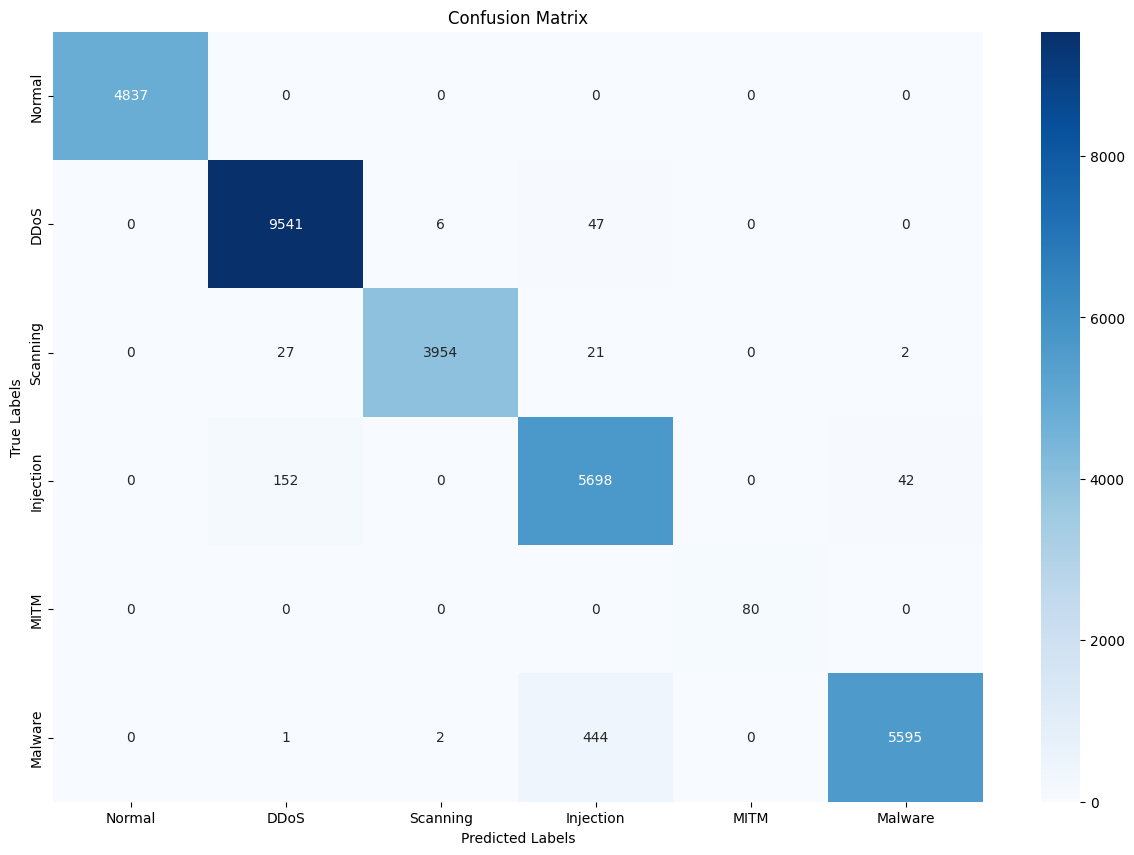

In [41]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

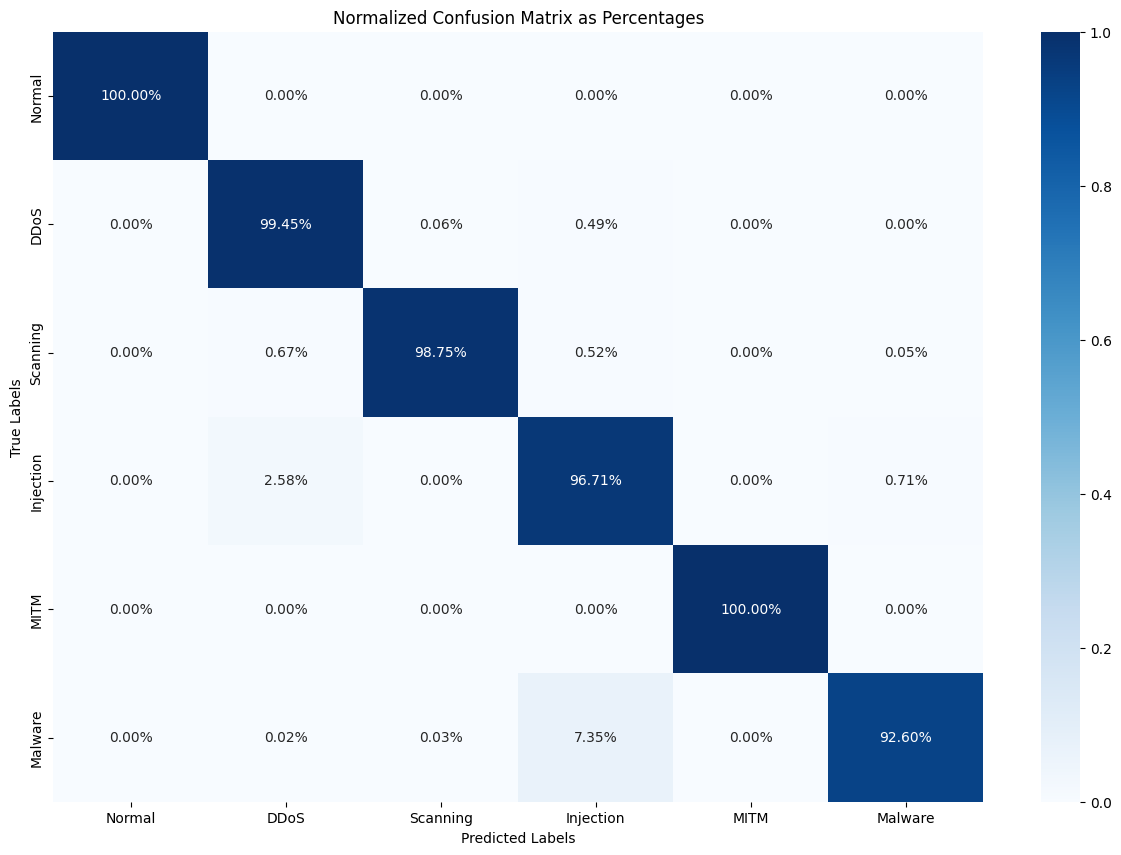

In [42]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()